# Day 2 · 02 — Lab: hyperparameter optimisation, what is worth tuning (30 min)

Two experiments on NHITS, both scored on the **validation window** (the 14 weeks before the test window), so
the test set stays untouched until the final refit:

1. **One-at-a-time sensitivity.** Move one hyperparameter at a time away from the default and measure how
   much validation RMSSE moves. Big spread → worth tuning; flat → leave the default.
2. **A small Optuna search** (`AutoNHITS`, TPE sampler) over the parameters that mattered, then fANOVA
   importances from the study.

Rule of thumb for N-BEATS / N-HiTS on retail data (check it against your own results below):

| Usually worth tuning | Usually not |
|---|---|
| `input_size` (lookback) | `mlp_units` width / depth |
| `learning_rate`, `max_steps` | `n_blocks`, number of stacks |
| `scaler_type` | activation function |
| `loss` (matches the metric?) | `n_pool_kernel_size` details |

In [1]:
import logging
import warnings

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd

import bootcamp as bc

warnings.filterwarnings("ignore")
logging.getLogger("pytorch_lightning").setLevel(logging.ERROR)
logging.getLogger("lightning").setLevel(logging.ERROR)
optuna.logging.set_verbosity(optuna.logging.WARNING)
palette = ["#000000", "#0072B2", "#D55E00", "#009E73", "#CC79A7", "#56B4E9", "#E69F00"]
plt.rcParams.update({"figure.figsize": (12, 5), "axes.prop_cycle": plt.cycler(color=palette)})

N_TRIALS = 8               # Optuna trials; 30+ is better if you have a GPU
# Each sensitivity fit takes ~30 s on a 4-core laptop CPU with all series. Run these four in class (~6 min) and
# hand the others to volunteers, or set RUN_ALL = True (~12 min more). The Optuna search takes ~12 min; the whole
# notebook ~18 min. Short of time: N_TRIALS = 4 halves the search.
RUN_PARAMS = ["input_size", "learning_rate", "loss", "mlp_units"]
RUN_ALL = False

/home/user/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from neuralforecast import NeuralForecast
from neuralforecast.auto import AutoNHITS
from neuralforecast.losses.pytorch import MAE, MSE, HuberLoss
from neuralforecast.models import NHITS

panel = bc.load_panel()
train, test = bc.split(panel)
fit_part, valid = bc.split(train, cutoff=bc.VALID_START)     # tune on this split only
Y_fit, Y_train = bc.to_nixtla(fit_part), bc.to_nixtla(train)
print(f"tuning fit: → {fit_part['ds'].max()} | validation: {valid['ds'].min()} → {valid['ds'].max()}")

2026-11-21 21:28:24,140	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


2026-11-21 21:28:24,347	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


tuning fit: → 2025-01-01 | validation: 2025-01-08 → 2025-04-09


## Intuition: tuning is a budget

Imagine a mixing desk with twenty knobs. Most change the sound very little; one or two change it a lot. The
sensitivity sweep finds out which knobs matter **before** you spend money searching over all of them. And every
gain must be compared with the noise floor, measured below by refitting the same model with different random
seeds: a knob whose effect is smaller than that is not a finding.

## 1. One-at-a-time sensitivity

In [3]:
# start_padding_enabled: the shortest series have 52 weeks left once the validation weeks are held out, fewer than
# the 56-week input in the grid; padding their start with zeros lets them take part (no effect on longer series).
DEFAULT = dict(input_size=2 * bc.H, learning_rate=1e-3, scaler_type="robust", loss=MAE(),
               mlp_units=[[512, 512]] * 3, n_blocks=[1, 1, 1], max_steps=bc.MAX_STEPS, start_padding_enabled=True)

GRID = {
    "input_size": [bc.H, 2 * bc.H, 4 * bc.H],
    "learning_rate": [1e-4, 1e-3, 5e-3],
    "scaler_type": ["identity", "standard", "robust"],
    "loss": [MAE(), MSE(), HuberLoss()],
    "max_steps": [bc.MAX_STEPS // 2, bc.MAX_STEPS, bc.MAX_STEPS * 2],
    "mlp_units": [[[128, 128]] * 3, [[512, 512]] * 3, [[1024, 1024]] * 3],
    "n_blocks": [[1, 1, 1], [2, 2, 2], [3, 3, 3]],
}


def label(v):
    return type(v).__name__ if hasattr(v, "is_distribution_output") else str(v[0][0]) + "w" if isinstance(v, list) and isinstance(v[0], list) else str(v)


_cache: dict[str, tuple[float, float]] = {}
valid_fc: dict[str, pd.DataFrame] = {}     # every validation forecast, saved below for any metric later


def valid_rmsse(seed: int = bc.RANDOM_SEED, **overrides) -> tuple[float, float]:
    params = {**DEFAULT, **overrides}
    key = repr(sorted((k, label(v)) for k, v in params.items())) + f"|seed={seed}"
    if key in _cache:                      # the default setting appears in every row of the grid
        return _cache[key]
    model = NHITS(h=bc.H, random_seed=seed, **params, **bc.trainer_kwargs())
    nf = NeuralForecast(models=[model], freq=bc.FREQ)
    with bc.Timer() as t:
        nf.fit(df=Y_fit)
    p = nf.predict()
    name = "NHITS|" + ",".join(f"{k}={label(v)}" for k, v in sorted(overrides.items())) + f"|seed={seed}"
    valid_fc[name] = p.rename(columns={"NHITS": name}).set_index(["unique_id", "ds"])[name]
    s = bc.summarise(bc.score(p, valid, fit_part, ["NHITS"]))
    _cache[key] = (s.loc[0, "mean_rmsse"], t.seconds)
    return _cache[key]


rows = []
for param, values in GRID.items():
    if not RUN_ALL and param not in RUN_PARAMS:
        continue
    for v in values:
        score, secs = valid_rmsse(**{param: v})
        rows.append({"param": param, "value": label(v), "valid_rmsse": score, "fit_seconds": secs})
        print(f"{param:14s} {label(v):>10s}  RMSSE {score:.4f}  ({secs:.0f}s)")
sens = pd.DataFrame(rows)

input_size             14  RMSSE 1.6511  (27s)


input_size             28  RMSSE 1.6136  (27s)


input_size             56  RMSSE 1.5412  (27s)


learning_rate      0.0001  RMSSE 1.6127  (26s)
learning_rate       0.001  RMSSE 1.6136  (27s)


learning_rate       0.005  RMSSE 1.6283  (26s)
loss                  MAE  RMSSE 1.6136  (27s)


loss                  MSE  RMSSE 1.8003  (26s)


loss            HuberLoss  RMSSE 1.6119  (25s)


mlp_units            128w  RMSSE 1.6199  (8s)
mlp_units            512w  RMSSE 1.6136  (27s)


mlp_units           1024w  RMSSE 1.6076  (77s)


param
loss             0.188377
input_size       0.109912
learning_rate    0.015612
mlp_units        0.012249
Name: spread, dtype: float64

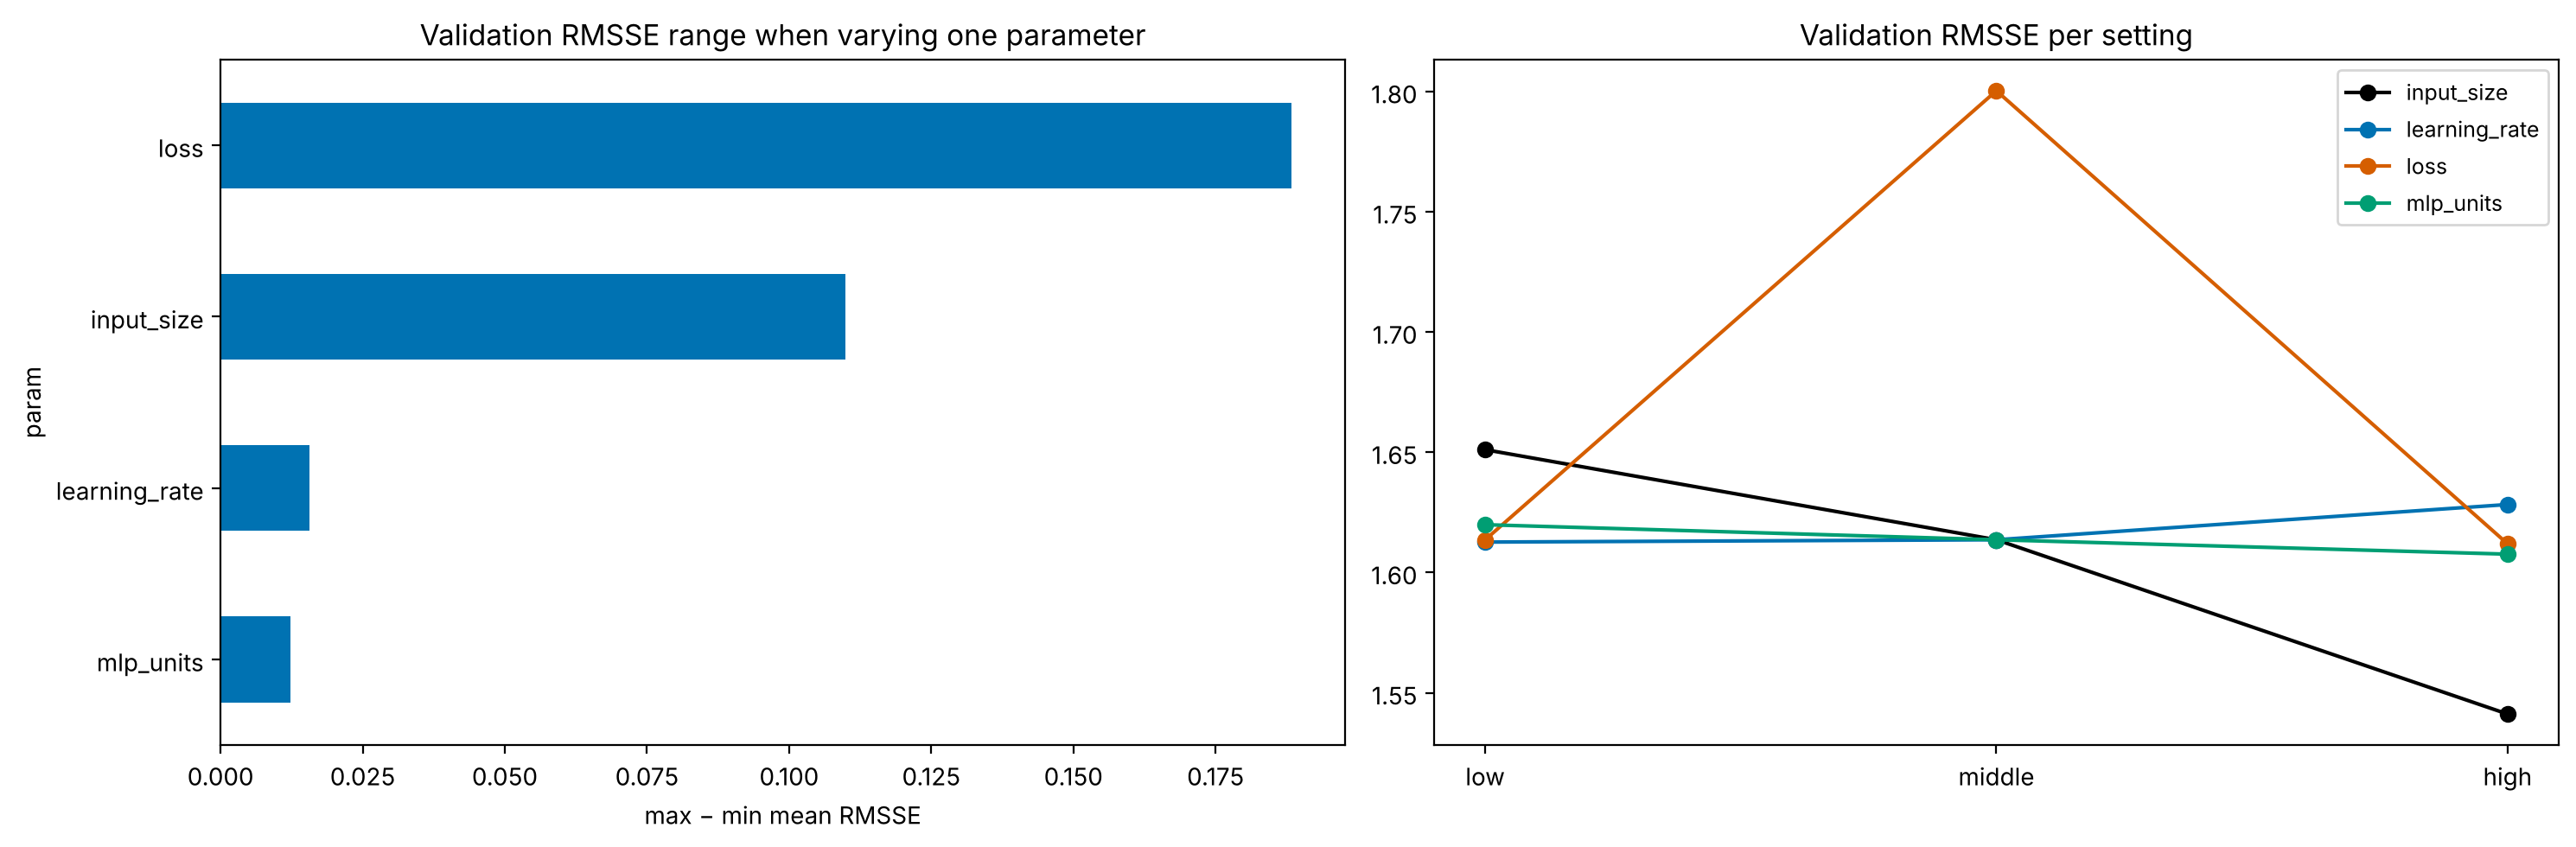

In [4]:
spread = (sens.groupby("param")["valid_rmsse"].agg(lambda s: s.max() - s.min())
          .sort_values(ascending=True).rename("spread"))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
spread.plot.barh(ax=axes[0], color=palette[1])
axes[0].set_title("Validation RMSSE range when varying one parameter")
axes[0].set_xlabel("max − min mean RMSSE")
for i, (param, g) in enumerate(sens.groupby("param")):
    axes[1].plot(range(len(g)), g["valid_rmsse"], marker="o", label=param)
axes[1].set_xticks([0, 1, 2], ["low", "middle", "high"])
axes[1].set_title("Validation RMSSE per setting")
axes[1].legend(fontsize=9)
plt.tight_layout()
spread.sort_values(ascending=False)

### The noise floor: same settings, different random seeds

A neural net starts from random weights and sees mini-batches in random order. Refit the **default** setting
with two more seeds: the spread you get is what "changing nothing" does to the score. A parameter whose spread
is not clearly bigger than this is not a finding.

In [5]:
seed_scores = [valid_rmsse()[0]] + [valid_rmsse(seed=s)[0] for s in (1, 2)]
seed_spread = max(seed_scores) - min(seed_scores)
bc.save_raw(pd.concat(valid_fc, axis=1).reset_index(), "02_hpo_grid", "valid", actuals=valid)
print("default setting, 3 seeds:", [round(x, 4) for x in seed_scores], f"| seed spread {seed_spread:.4f}")
print("parameters whose spread beats the seed spread:", list(spread[spread > seed_spread].sort_values(ascending=False).index))

default setting, 3 seeds: [np.float64(1.6136), np.float64(1.5941), np.float64(1.6077)] | seed spread 0.0195
parameters whose spread beats the seed spread: ['loss', 'input_size']


**Read the chart before the search.** Parameters at the bottom of the bar chart are not worth search budget:
fix them at the default. A parameter whose effect is smaller than the seed spread above is not a finding.

### Reading the result

* In the reference run the **loss** was the biggest knob: validation RMSSE ≈ 1.61 with MAE or Huber, ≈ 1.80
  with MSE. MSE squares the error, so it chases the rare promo spikes and overshoots every normal week.
* The **lookback** came second (≈ 1.65 with 14 weeks, ≈ 1.54 with 56). Width and learning rate moved the score by
  less than 0.02.

*Reference run: all 17,241 eligible series, 4-core laptop CPU, 500 steps. Your numbers will differ a little; the
reading should not.*

## 2. A small Optuna search over what mattered

`AutoNHITS` with the Optuna backend uses its own internal validation split (`val_size`), here the last
14 weeks of the training data. The config function is the search space.

In [6]:
def config(trial: optuna.Trial) -> dict:
    return {
        "input_size": trial.suggest_categorical("input_size", [bc.H, 2 * bc.H, 3 * bc.H, 4 * bc.H]),
        "learning_rate": trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True),
        "scaler_type": trial.suggest_categorical("scaler_type", ["standard", "robust"]),
        "max_steps": trial.suggest_categorical("max_steps", [bc.MAX_STEPS, 2 * bc.MAX_STEPS]),
        "mlp_units": [[512, 512]] * 3,                 # fixed: not worth tuning
        "start_padding_enabled": True,                 # as in the sensitivity runs
        "random_seed": bc.RANDOM_SEED,
        **bc.trainer_kwargs(),
    }


auto = AutoNHITS(h=bc.H, loss=MAE(), valid_loss=MAE(), config=config, backend="optuna",
                 search_alg=optuna.samplers.TPESampler(seed=bc.RANDOM_SEED), num_samples=N_TRIALS)
nf = NeuralForecast(models=[auto], freq=bc.FREQ)
with bc.Timer() as t_hpo:
    nf.fit(df=Y_train, val_size=bc.H)
study = nf.models[0].results
print(f"{N_TRIALS} trials in {t_hpo.seconds:.0f}s | best valid MAE {study.best_value:.3f}")
study.best_params

8 trials in 538s | best valid MAE 1329.698


{'input_size': 56,
 'learning_rate': 0.0011973004661630607,
 'scaler_type': 'standard',
 'max_steps': 1000}

In [7]:
trials = study.trials_dataframe()[["number", "value", "params_input_size", "params_learning_rate",
                                   "params_scaler_type", "params_max_steps"]].sort_values("value")
try:
    importance = optuna.importance.get_param_importances(study)
    print("fANOVA importance:", {k: round(v, 3) for k, v in importance.items()})
except Exception as e:                       # needs enough completed trials
    print("importance not available:", e)
trials.head(8)

fANOVA importance: {'learning_rate': 0.98, 'input_size': 0.013, 'scaler_type': 0.007, 'max_steps': 0.0}


,number,value,params_input_size,params_learning_rate,params_scaler_type,params_max_steps
0,0,1329.697998,56,0.001197,standard,1000
4,4,1401.053711,42,0.005463,robust,1000
2,2,1422.094360,28,0.001011,standard,1000
6,6,1426.585205,56,0.002684,robust,500
1,1,1429.382202,42,0.006570,robust,1000
3,3,1471.977051,14,0.000178,standard,1000
7,7,1502.801147,14,0.004732,standard,1000
5,5,1564.580200,14,0.000995,robust,500


## 3. Refit the winner and score it on the test window

In [8]:
fcst = nf.predict().rename(columns={"AutoNHITS": "NHITS_tuned"})
bc.save_forecasts(fcst, "02_hpo", actuals=test)
bc.save_raw(fcst, "02_hpo", "test", actuals=test)
bc.record(fcst, test, train, lab="02 HPO", fit_seconds=t_hpo.seconds,
          notes=f"{N_TRIALS} TPE trials; best {study.best_params}")
bc.leaderboard()[["model", "mean_rmsse", "median_rmsse", "wape", "bias_pct", "fit_seconds", "lab"]]

,model,mean_rmsse,median_rmsse,wape,bias_pct,fit_seconds,lab
1,NHITS_tuned,1.326662,0.600483,0.301265,-0.031618,538.412443,02 HPO
2,LightGBM,1.353564,0.568860,0.291112,0.113513,5.597691,00 day1 reference
3,NHITS,1.389044,0.638116,0.334167,-0.029529,27.301527,01 GFM default
4,NBEATS_generic,1.408790,0.634459,0.324974,-0.055147,25.672427,01 GFM default
5,NBEATS_interpretable,1.409052,0.631084,0.324051,-0.059228,18.668830,01 GFM default
6,AutoETS,1.481539,0.694911,0.402428,0.059910,17.583231,00 day1 reference
7,Naive,1.516040,0.744972,0.420019,0.023080,17.583231,00 day1 reference
8,DLinear,1.593781,0.783190,0.443576,-0.053009,3.873696,01 GFM default
9,SeasonalNaive,1.709260,0.912763,0.445609,-0.008208,17.583231,00 day1 reference


### Reading the result

![Lab 02 results](slides/img/res_lab02.png)

* **The noise floor.** Refitting the default with three seeds moved validation RMSSE by ≈ 0.02. Only two
  parameters beat that: the **loss** (spread 0.19: MSE chases the few huge weeks and is ≈ 12 % worse) and the
  **lookback** (0.11: 56 weeks, a full year, beats 14 or 28). Width and learning rate (≈ 0.01–0.02) are inside
  the noise: not findings.
* **Optuna**: 8 trials took ≈ 540 s and picked the 56-week lookback; test RMSSE moved from ≈ 1.389 to ≈ 1.327.
  That is **20× the compute of one default fit for ≈ 4.5 %**, enough to pass Day 1's LightGBM (≈ 1.354, 6 s), but
  most of the gain is the lookback the sweep had already found for the price of three fits.
* fANOVA credits the learning rate with almost all the importance (0.98), but that is importance *within the
  ranges we searched*, from 8 points. The one-at-a-time sweep is the more honest picture of what is worth tuning.
* Rule of thumb: get the **loss**, the **lookback** and the **scaling** right, check gains against seed noise,
  then stop tuning.

*Reference run: all 17,241 eligible series, 4-core laptop CPU, 500 steps. Your numbers will differ a little; the
reading should not.*

## Discussion

* How much of the gain came from **one** parameter (usually the lookback)? Could you have got it with a
  three-point manual sweep instead of a search?
* The search cost N× the default fit. Compare the RMSSE gain per CPU-minute with Day 1's LightGBM.
* Tuning on a single validation window overfits that window. With more budget, score each trial with
  `cross_validation(n_windows=3)` instead.